# Pronóstico de ventas por SKU
## Parte 2: baselines

Naive, Seasonal Naive, media histórica y medias móviles de 3, 6 y 12 meses. Son la referencia que cualquier modelo más complejo tiene que superar.

Esquema de evaluación:
- Validación: cortes mensuales de diciembre 2022 a agosto 2024. Se evalúan los pronósticos de enero 2023 a noviembre 2024.
- Test: diciembre 2024 a mayo 2025.
- En cada corte se entrena con todo lo disponible hasta ese mes inclusive y se pronostican los 3 meses siguientes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from funciones import cargar_ventas, naive, seasonal_naive, media, media_movil, walk_forward, metricas

In [ ]:
ventas = cargar_ventas()
skus = ["A", "B", "C", "D", "E"]

cortes_validacion = pd.date_range("2022-12-01", "2024-08-01", freq="MS")
print("Cortes:", len(cortes_validacion))
cortes_validacion

Cortes: 21


DatetimeIndex(['2022-12-01', '2023-01-01', '2023-02-01', '2023-03-01',
               '2023-04-01', '2023-05-01', '2023-06-01', '2023-07-01',
               '2023-08-01', '2023-09-01', '2023-10-01', '2023-11-01',
               '2023-12-01', '2024-01-01', '2024-02-01', '2024-03-01',
               '2024-04-01', '2024-05-01', '2024-06-01', '2024-07-01',
               '2024-08-01'],
              dtype='datetime64[us]', freq='MS')

## Modelos

- Naive: el próximo mes es igual al último observado.
- Seasonal Naive: el próximo mes es igual al mismo mes del año anterior.
- Media: el promedio de toda la historia disponible.
- Media móvil: el promedio de los últimos 3, 6 o 12 meses.

In [11]:
modelos = {
    "Naive": naive,
    "Seasonal Naive": seasonal_naive,
    "Media": media,
    "Media M3": lambda train, h: media_movil(train, h, 3),
    "Media M6": lambda train, h: media_movil(train, h, 6),
    "Media M12": lambda train, h: media_movil(train, h, 12),
}

resultados = walk_forward(ventas, skus, modelos, cortes_validacion)
resultados.head()

,SKU,Modelo,Corte,Horizonte,Fecha,Real,Pronostico,Escala,Error,ErrorAbs
0,A,Naive,2022-12-01,1,2023-01-01,34,37.0,16.73913,3.0,3.0
1,A,Naive,2022-12-01,2,2023-02-01,13,37.0,16.73913,24.0,24.0
2,A,Naive,2022-12-01,3,2023-03-01,19,37.0,16.73913,18.0,18.0
3,A,Seasonal Naive,2022-12-01,1,2023-01-01,34,37.0,16.73913,3.0,3.0
4,A,Seasonal Naive,2022-12-01,2,2023-02-01,13,25.0,16.73913,12.0,12.0


## Resultados por SKU

In [12]:
tabla = resultados.groupby(["SKU", "Modelo"]).apply(metricas)
tabla["MASE"].unstack().round(2)

Modelo,Media,Media M12,Media M3,Media M6,Naive,Seasonal Naive
SKU,,,,,,
A,0.94,1.00,1.09,1.21,0.92,0.84
B,0.83,0.81,0.87,0.87,1.16,1.31
C,1.07,1.20,1.37,1.24,1.50,1.60
D,1.27,1.43,1.42,1.32,1.59,2.25
E,2.40,1.91,2.01,2.26,1.68,2.36


In [13]:
tabla["Sesgo"].unstack().round(1)

Modelo,Media,Media M12,Media M3,Media M6,Naive,Seasonal Naive
SKU,,,,,,
A,2.4,0.8,-1.7,-1.2,-1.6,2.8
B,-12.5,-10.4,-7.3,-9.9,-5.1,-9.7
C,-1.1,-1.3,-0.8,-1.6,-0.3,-1.2
D,-7.6,-15.8,-5.5,-10.0,-1.0,-23.3
E,-38.6,-26.4,-17.3,-21.2,-11.9,-35.0


- A: el Seasonal Naive es el mejor (0.84). El segundo semestre alto de A se repitió en 2023 y 2024, y copiar el mismo mes del año anterior lo aprovecha.
- B: la media móvil de 12 meses (0.81) y la media (0.83) quedan casi iguales. Todos subestiman, por el salto de mayo 2024.
- C: la media es la mejor, pero con MASE mayor a 1 (1.07). C es casi todo ruido.
- D: la media es la mejor (1.27). Los errores son altos para todos porque la validación incluye el período anómalo de 2022-2023.
- E: el Naive es el mejor (1.68). La validación incluye el salto de julio 2023 y todos los modelos subestiman.

## Por horizonte

In [14]:
resultados.groupby(["SKU", "Modelo", "Horizonte"]).apply(metricas)["MASE"].unstack().round(2)

Horizonte              1     2     3
SKU Modelo                          
A   Media           0.95  0.96  0.92
    Media M12       1.01  1.01  0.97
    Media M3        0.89  1.11  1.27
    Media M6        1.08  1.24  1.31
    Naive           0.77  0.90  1.10
    Seasonal Naive  0.82  0.86  0.83
B   Media           0.84  0.78  0.87
    Media M12       0.84  0.76  0.82
    Media M3        0.91  0.82  0.87
    Media M6        0.83  0.87  0.90
    Naive           1.11  1.32  1.05
    Seasonal Naive  1.26  1.27  1.41
C   Media           1.05  1.07  1.09
    Media M12       1.17  1.19  1.24
    Media M3        1.25  1.43  1.44
    Media M6        1.14  1.26  1.33
    Naive           1.25  1.57  1.69
    Seasonal Naive  1.60  1.59  1.61
D   Media           1.26  1.27  1.27
    Media M12       1.42  1.43  1.45
    Media M3        1.51  1.49  1.26
    Media M6        1.42  1.36  1.19
    Naive           1.45  1.78  1.55
    Seasonal Naive  2.21  2.21  2.34
E   Media           2.20  2.38  2.61
    Media M12       1.75  1.89  2.10
    Media M3        1.53  2.02  2.47
    Media M6        1.91  2.28  2.59
    Naive           1.21  1.67  2.17
    Seasonal Naive  2.30  2.35  2.44

- El Naive es el mejor a 1 mes en A (0.77) y E (1.21), pero empeora rápido: a 3 meses sube a 1.10 en A y a 2.17 en E.
- El Seasonal Naive de A se mantiene parejo en los tres horizontes (entre 0.82 y 0.86).
- En B, C y D la media y la media móvil de 12 son estables entre horizontes, porque pronostican el mismo valor para los tres meses.

## Junio a agosto

Es la temporada que hay que pronosticar. Son 18 pronósticos por SKU: junio, julio y agosto de 2023 y de 2024, cada uno desde tres cortes distintos.

In [15]:
jun_ago = resultados[resultados["Fecha"].dt.month.isin([6, 7, 8])]
jun_ago.groupby(["SKU", "Modelo"]).apply(metricas)["MASE"].unstack().round(2)

Modelo,Media,Media M12,Media M3,Media M6,Naive,Seasonal Naive
SKU,,,,,,
A,1.01,1.15,1.48,1.49,1.20,0.96
B,0.95,0.91,0.80,0.84,1.45,1.24
C,0.99,1.01,1.70,1.31,1.82,1.27
D,1.32,1.49,1.77,1.44,1.75,2.04
E,3.15,2.50,3.06,3.11,2.64,2.12


- En A y E el mejor en junio-agosto es el Seasonal Naive (0.96 y 2.12). En E el Naive cae a 2.64: en esos meses arranca el semestre alto y el último dato queda corto.
- En B la mejor es la media móvil de 3 meses (0.80) y en C y D la media.

## Baseline a superar por SKU

In [25]:
mase = tabla["MASE"].unstack()
mejor_baseline = mase.idxmin(axis=1)

pd.DataFrame({
    "Mejor baseline": mejor_baseline,
    "MASE": mase.min(axis=1),
    "Sesgo": [tabla.loc[(s, mejor_baseline[s]), "Sesgo"] for s in skus],
}).round(2)

,Mejor baseline,MASE,Sesgo
SKU,,,
A,Seasonal Naive,0.84,2.81
B,Media M12,0.81,-10.39
C,Media,1.07,-1.05
D,Media,1.27,-7.56
E,Naive,1.68,-11.90


## Pronóstico a 3 meses contra lo real

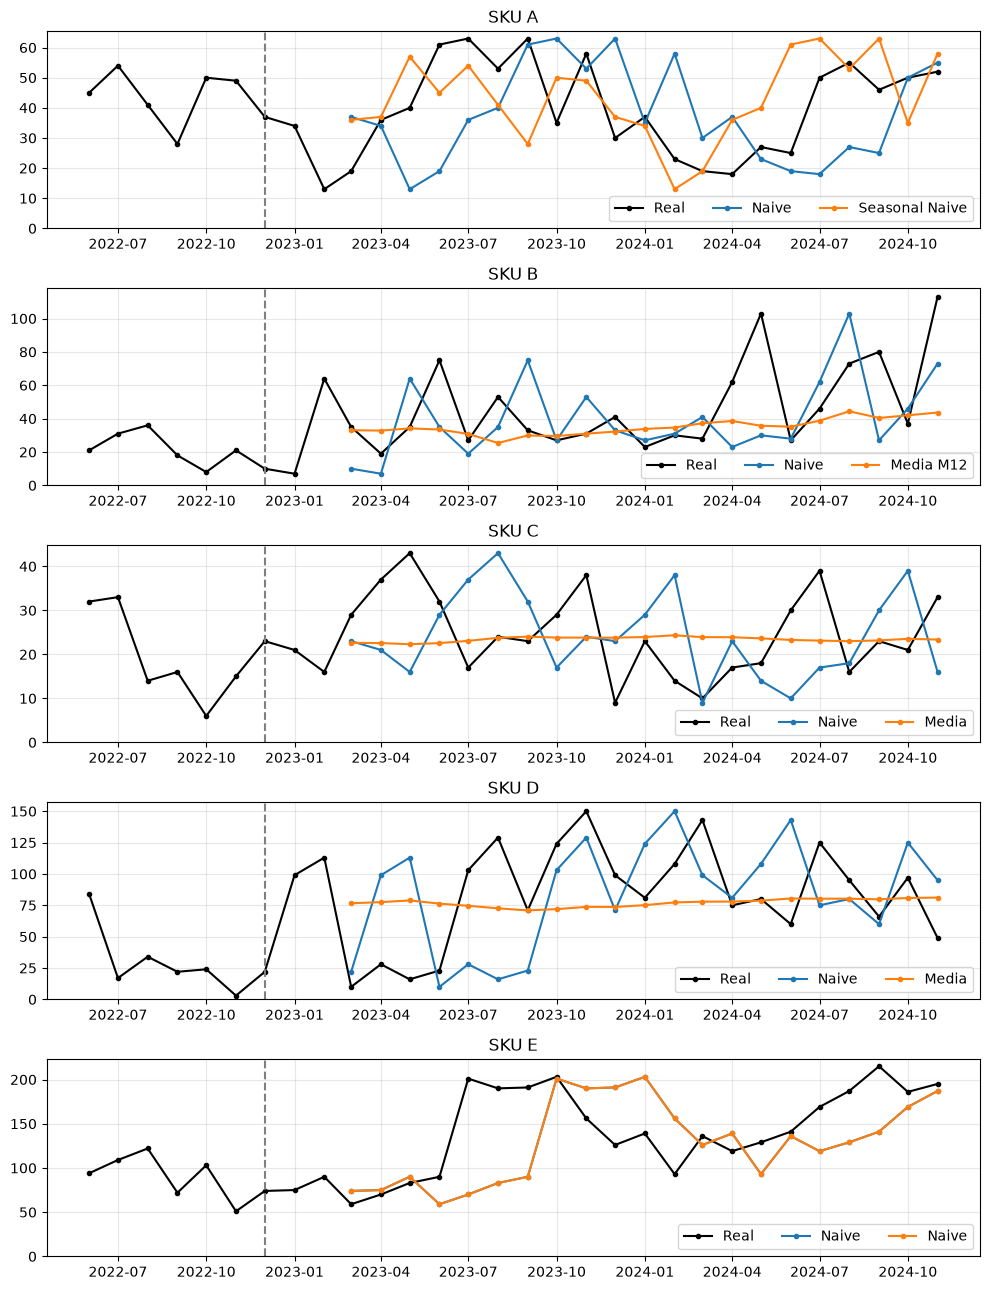

In [33]:
fig, axes = plt.subplots(5, 1, figsize=(10, 13))
mes = resultados[resultados["Horizonte"] == 3]

for i, s in enumerate(skus):
    axes[i].plot(ventas.loc["2022-06-01":"2024-11-01", s], color="black", marker="o", markersize=3, label="Real")
    for nombre in ["Naive", mejor_baseline[s]]:
        p = mes[(mes["SKU"] == s) & (mes["Modelo"] == nombre)]
        axes[i].plot(p["Fecha"], p["Pronostico"], marker="o", markersize=3, label=nombre)
    axes[i].set_title(f"SKU {s}")
    axes[i].axvline(cortes_validacion[0], color="gray", linestyle="--")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.3)
    axes[i].legend(ncol=3, fontsize=10)

plt.tight_layout()
plt.show()